In [1]:
# Paths (originally Google Drive on Colab; now relative to this notebook folder)
import os
DATA_DIR = os.environ.get("QA_DATA_DIR", "datasets/ViWikiQA1.0")
OUTPUT_DIR = os.environ.get("QA_OUTPUT_DIR", "model/phobert-qa-pytorch")
print("Data dir  :", DATA_DIR, os.listdir(DATA_DIR))
print("Output dir:", OUTPUT_DIR)


Data dir  : datasets/ViWikiQA1.0 ['ws_test.csv', 'ws_dev.csv', 'ws_train.csv']
Output dir: model/phobert-qa-pytorch


In [2]:
%pip install -q transformers datasets torch pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


# 1. Import libs

In [3]:
import os, sys, argparse, gc, re, collections, string
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering
import datasets
from typing import Any


# 2. Run code

In [4]:
print("Torch Version: ", torch.__version__, "| CUDA:", torch.cuda.is_available())

#########################################################
MODEL_PHOBERT_BASE = 'vinai/phobert-base'
MODEL_PHOBERT_LARGE = 'vinai/phobert-large'

#########################################################
def get_arguments():
    parser = argparse.ArgumentParser()
    # phobert-large needs a GPU; on CPU phobert-base is used by default (override with env QA_MODEL)
    parser.add_argument("--model", type=str, default=os.environ.get("QA_MODEL", MODEL_PHOBERT_LARGE if torch.cuda.is_available() else MODEL_PHOBERT_BASE), help="Pretrained model bert")
    parser.add_argument("--lr", type=float, default=3e-5, help="Learning rate")
    parser.add_argument("--bs", type=int, default=16, help="Batch size")
    parser.add_argument("--epochs", type=int, default=20, help="Number of epochs")
    # PhoBERT has max_position_embeddings=258 -> at most 256 tokens (512 would crash)
    parser.add_argument("--maxlen", type=int, default=256, help="Max sentence length")
    parser.add_argument("--stride", type=int, default=128, help="Stride value for window slide")
    parser.add_argument("--use_fast", type=bool, default=True, help="Tokenize sentence with fast bpe")

    return parser.parse_args(args=[])

#########################################################
def preprocess_dataset(ds: dict, tokenizer: Any, maxlen: int):
    questions = [q.strip() for q in ds["question"]]
    contexts = [str(t) for t in ds["context"]]

    tokenized = tokenizer(
        questions,
        contexts,
        max_length=maxlen,
        truncation="only_second",
        return_token_type_ids=True,
        padding="max_length",
    )

    # Re-build a clean dictionary containing only plain lists to prevent serialization issues
    inputs = {
        "input_ids": list(tokenized["input_ids"]),
        "attention_mask": list(tokenized["attention_mask"]),
        "token_type_ids": list(tokenized["token_type_ids"]),
    }

    answer_starts = ds["answer_start"]
    answer_ends = ds["answer_end"]
    answers = ds["answer"]
    start_positions = []
    end_positions = []
    assert len(answer_starts) == len(answer_ends)

    for i in range(len(answer_starts)):
        start_char = answer_starts[i]
        end_char = answer_ends[i]
        if start_char == 0 and end_char == 0:
            start_positions.append(0)
            end_positions.append(0)
            continue

        answer = answers[i]
        context = contexts[i]
        input_ids = inputs["input_ids"][i]

        # Find the start and end of the context
        idx = 0
        while idx < len(input_ids) and input_ids[idx] != 2:
            idx += 1
        if idx < len(input_ids):
            idx += 2
        context_start = idx

        while idx < len(input_ids) and input_ids[idx] != 1:
            idx += 1
        context_end = idx - 1
        if context_end < len(input_ids) and input_ids[context_end] == 2:
            context_end -= 1

        pre_ans = tokenizer.encode(context[:start_char], add_special_tokens=False)
        ans_ids = tokenizer.encode(answer, add_special_tokens=False)

        start_position = context_start + len(pre_ans)
        end_position = start_position + len(ans_ids) - 1

        # If the answer is not fully inside the context, label is (0, 0)
        if start_position < context_start or end_position > context_end:
            start_positions.append(0)
            end_positions.append(0)
        else:
            # Otherwise it's the start and end token positions
            start_positions.append(start_position)
            end_positions.append(end_position)

    inputs["start_positions"] = start_positions
    inputs["end_positions"] = end_positions
    return inputs

#########################################################
def load_split(file_name: str, n: int = None):
    df = pd.read_csv(file_name)
    df.drop("title", axis=1, inplace=True, errors='ignore')
    df.fillna({"answer": ""}, inplace=True)
    if n:
        df = df.sample(n=min(n, len(df)), random_state=42).reset_index(drop=True)
    return df


Torch Version:  2.15.0+cu132 | CUDA: False


In [5]:
if __name__ == "__main__":
    args = get_arguments()
    model_name = args.model
    lr = args.lr
    use_cuda = torch.cuda.is_available()
    # Full setting on GPU; reduced setting on CPU so that the notebook finishes in reasonable time
    batch_size = int(os.environ.get("QA_BS", 16 if use_cuda else 8))
    epochs = int(os.environ.get("QA_EPOCHS", 10 if use_cuda else 1))
    n_train = int(os.environ.get("QA_N_TRAIN", 0 if use_cuda else 2000)) or None   # None = full train set
    n_val = int(os.environ.get("QA_N_VAL", 0 if use_cuda else 300)) or None
    maxlen = args.maxlen
    stride = args.stride
    use_fast = args.use_fast
    torch.manual_seed(42)


In [6]:
# separate so that later test runs, we don't execute (train) again

if __name__ == "__main__":
    print("##############################")
    print("Model :", model_name)
    print("Learning Rate :", lr)
    print("Batch Size :", batch_size)
    print("Epochs :", epochs)
    print("Max Token Length :", maxlen)
    print("Stride :", stride)
    print("Use Fast :", use_fast)
    print("Train / Val samples :", n_train or "all", "/", n_val or "all")
    print("##############################")

    import time
    from torch.optim import AdamW
    from torch.utils.data import DataLoader
    from transformers import get_linear_schedule_with_warmup

    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)
    cols = ["input_ids", "attention_mask", "token_type_ids", "start_positions", "end_positions"]

    df_tr = load_split(os.path.join(DATA_DIR, "ws_train.csv"), n_train)
    ds_tr = datasets.Dataset.from_pandas(df_tr)
    dataset_tr = ds_tr.map(lambda x: preprocess_dataset(x, tokenizer, maxlen), batched=True, remove_columns=ds_tr.column_names)
    dataset_tr.set_format(type="torch", columns=cols)

    df_val = load_split(os.path.join(DATA_DIR, "ws_dev.csv"), n_val)
    ds_val = datasets.Dataset.from_pandas(df_val)
    dataset_val = ds_val.map(lambda x: preprocess_dataset(x, tokenizer, maxlen), batched=True, remove_columns=ds_val.column_names)
    dataset_val.set_format(type="torch", columns=cols)

    train_loader = DataLoader(dataset_tr, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(dataset_val, batch_size=batch_size)

    device = torch.device("cuda" if use_cuda else "cpu")
    model = AutoModelForQuestionAnswering.from_pretrained(model_name)
    model.to(device)

    optimizer = AdamW(model.parameters(), lr=lr)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

    def run_batch(batch):
        batch = {k: v.to(device) for k, v in batch.items()}
        return model(**batch)

    print("Starting PyTorch Training Loop on device:", device)
    best_val = float("inf")
    for epoch in range(epochs):
        model.train()
        total_loss, t0 = 0, time.time()
        for step, batch in enumerate(train_loader, 1):
            optimizer.zero_grad()
            loss = run_batch(batch).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()
            if step % 25 == 0 or step == len(train_loader):
                print(f"  epoch {epoch+1} step {step}/{len(train_loader)} - loss {total_loss/step:.4f} - {time.time()-t0:.0f}s")
        avg_train_loss = total_loss / len(train_loader)

        # Validation
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                total_val_loss += run_batch(batch).loss.item()
        avg_val_loss = total_val_loss / len(val_loader)

        print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_train_loss:.4f} - Val Loss: {avg_val_loss:.4f}")

        # Save the best model (lowest validation loss), like the original Keras callback
        if avg_val_loss <= best_val:
            best_val = avg_val_loss
            os.makedirs(OUTPUT_DIR, exist_ok=True)
            model.save_pretrained(OUTPUT_DIR)
            tokenizer.save_pretrained(OUTPUT_DIR)
            print(f"save model at epoch {epoch+1} -> {OUTPUT_DIR}")

    print("Model saved successfully!")


##############################
Model : /home/user/LAB/models/phobert-base
Learning Rate : 3e-05
Batch Size : 8
Epochs : 1
Max Token Length : 256
Stride : 128
Use Fast : True
Train / Val samples : 2000 / 300
##############################


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForQuestionAnswering LOAD REPORT from: /home/user/LAB/models/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
qa_outputs.bias             | MISSING    | 
qa_outputs.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting PyTorch Training Loop on device: cpu


... (9 outputs left out)

  epoch 1 step 250/250 - loss 1.9385 - 2005s


Epoch 1/1 - Loss: 1.9385 - Val Loss: 0.9621


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

save model at epoch 1 -> model/phobert-qa-pytorch
Model saved successfully!


In [7]:
sample = dataset_tr[0]
print({k: v[:20] if v.dim() else v for k, v in sample.items()})
print("Answer tokens:", tokenizer.decode(sample["input_ids"][sample["start_positions"]:sample["end_positions"]+1]))


{'input_ids': tensor([    0,    92,   392,     9,  1102, 12580,   335,   335,  1645,  9764,
           54,  1102, 12580,    10,   370,    67,    91,   277,   467,   114]), 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]), 'token_type_ids': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'start_positions': tensor(71), 'end_positions': tensor(134)}
Answer tokens: William_Lloyd_Garrison xuất_bản nhật_báo có ảnh_hưởng nhất trong số_nhiều nhật_báo chống chủ_nghĩa nô_lệ , đó là tờ The_Liberator trong khi đó Frederick_Douglass , một cựu nô_lệ , bắt_đầu viết cho tờ báo này vào_khoảng năm 1840 và khởi_sự tờ báo chống chủ_nghĩa nô_lệ của chính mình , đó là tờ North_Star năm 1847 .


# 3. Load Test Data

In [8]:
df_test = pd.read_csv(os.path.join(DATA_DIR, "ws_test.csv"))
df_test.drop("title", axis=1, inplace=True)
df_test.fillna({"answer": ""}, inplace=True)
df_test.info()


<class 'pandas.DataFrame'>
RangeIndex: 2210 entries, 0 to 2209
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   context       2210 non-null   str  
 1   question      2210 non-null   str  
 2   answer        2210 non-null   str  
 3   answer_start  2210 non-null   int64
 4   answer_end    2210 non-null   int64
dtypes: int64(2), str(3)
memory usage: 3.1 MB


<Axes: >

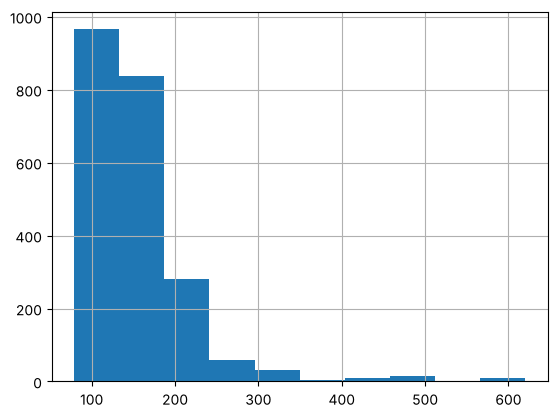

In [9]:
df_test["context_len"] = df_test["context"].apply(lambda x: len(x.split()))
df_test["context_len"].hist()

In [10]:
tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
ds_test = datasets.Dataset.from_pandas(df_test)

dataset_test = ds_test.map(
    lambda ds: preprocess_dataset(ds, tokenizer, maxlen),
    batched=True,
    remove_columns=ds_test.column_names,
)
len(ds_test), len(dataset_test)
#dataset_test
#dataset_test[0]['end_positions']

Map:   0%|          | 0/2210 [00:00<?, ? examples/s]

(2210, 2210)

# 4. Load model

In [11]:
# Load the fine-tuned PyTorch model saved by the training loop
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR, use_fast=True)
model = AutoModelForQuestionAnswering.from_pretrained(OUTPUT_DIR).to(device)
model.eval()
print(model.__class__.__name__, f"{sum(p.numel() for p in model.parameters()):,} parameters")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

RobertaForQuestionAnswering 134,409,218 parameters


# 5. Predict

In [12]:
def tokenize_question_context(question, context, tokenizer, maxlen, stride):
    question = question.strip()
    context = context.strip()
    inputs = tokenizer(
        question,
        context,
        max_length=maxlen,
        truncation="only_second",
        stride=stride,
        # return_overflowing_tokens=True,
        # return_offsets_mapping=True,
        padding="max_length",
        return_tensors="pt"
    )

    return inputs

def predict(model, question, context, tokenizer, maxlen, stride):
    inputs = tokenize_question_context(question, context, tokenizer, maxlen, stride)
    with torch.no_grad():
        outputs = model(**{k: v.to(model.device) for k, v in inputs.items()})

    start_logits = outputs["start_logits"].cpu().numpy()
    end_logits = outputs["end_logits"].cpu().numpy()

    starts = np.argmax(start_logits, axis=1)
    ends = np.argmax(end_logits,  axis=1)

    start_scores = np.max(start_logits, axis=1)
    end_scores = np.max(end_logits, axis=1)
    scores = start_scores + end_scores

    indices = []
    for idx, start in enumerate(starts):
        end = ends[idx]
        if start == 0 and end == 0:
            continue
        if end < start:
            continue
        indices.append(idx)

    answers = []
    for idx in indices:
        score = scores[idx]
        ans_ids = inputs["input_ids"][idx][starts[idx]:ends[idx]+1].tolist()
        answer = tokenizer.decode(ans_ids, skip_special_tokens=True)
        answers.append((answer, float(score)))
    return answers


df = df_test[df_test["context_len"] > 500]
df.head()

,context,question,answer,answer_start,answer_end,context_len
423,Khoảng 20 triệu năm sau ( 340 triệu năm trước ...,Bò_sát xuất_hiện từ khi nào ?,Khoảng 20 triệu năm sau ( 340 triệu năm trước ...,0,232,586
424,Khoảng 20 triệu năm sau ( 340 triệu năm trước ...,Đợt tuyệt_chủng lớn nhất diễn ra khi nào ?,Sự_kiện tuyệt_chủng lớn nhất cho tới nay diễn ...,830,1044,586
425,Khoảng 20 triệu năm sau ( 340 triệu năm trước ...,Khủng_long ngự_trị Trái_Đất vào kỷ nào ?,Một cuộc tuyệt_chủng ở thời_gian giữa hai kỷ T...,1218,1439,586
426,Khoảng 20 triệu năm sau ( 340 triệu năm trước ...,Các siêu lục_địa Laurasia và Gondwana có nguồn...,"180 triệu năm trước ( 11:03 chiều ) , Pangea v...",1577,1653,586
427,Khoảng 20 triệu năm sau ( 340 triệu năm trước ...,Thiên_thạch đã chấm_dứt thời_đại khủng_long có...,Bằng_chứng sớm nhất về thực_vật hạt_kín tiến_h...,1873,2436,586


In [13]:
df_test.head()

,context,question,answer,answer_start,answer_end,context_len
0,"Năm 1871 , Đức trở_thành một quốc_gia dân_tộc ...",Cộng_hoà Weimar chính_thức thay_thế đế_quốc Đứ...,Sau Chiến_tranh thế_giới thứ nhất và Cách_mạng...,122,253,90
1,"Năm 1871 , Đức trở_thành một quốc_gia dân_tộc ...",Nước Đức hiện_nay sự hợp_thành của hai nước nà...,"Sau một giai_đoạn Đồng_Minh chiếm_đóng , hai n...",369,488,90
2,"Năm 1871 , Đức trở_thành một quốc_gia dân_tộc ...",Hậu_quả nào đã xảy ra khi tại Đức chế_độ độc_t...,Chế_độ độc_tài quốc xã được hình_thành vào năm...,254,368,90
3,"Năm 1871 , Đức trở_thành một quốc_gia dân_tộc ...",Cộng_hoà Liên_bang Đức và Cộng_hoà Dân_chủ Đức...,"Năm 1990 , quốc_gia được tái thống_nhất .",489,530,90
4,"Trong thế_kỷ XXI , Đức là một đại cường_quốc v...","Vào năm 2015 , cả hai lĩnh_vực nào Đức đều xếp...",Đức đứng hàng_đầu thế_giới trong một_số lĩnh_v...,140,293,96


In [14]:
idx = 4
# question = df.loc[idx, "question"]
# context = df.loc[idx, "context"]
question = df_test.loc[idx, "question"]
print("Question:", question)
context = df_test.loc[idx, "context"]
print("Context:", context)

answers = predict(model, question, context, tokenizer, maxlen, stride)
print("Answer:",answers)

Question: Vào năm 2015 , cả hai lĩnh_vực nào Đức đều xếp ở vị_trí thứ ba thế_giới ?
Context: Trong thế_kỷ XXI , Đức là một đại cường_quốc và có kinh_tế lớn thứ tư thế_giới theo GDP danh_nghĩa , lớn thứ năm theo sức_mua tương_đương . Đức đứng hàng_đầu thế_giới trong một_số lĩnh_vực công_nghiệp và công_nghệ , và là nước xuất_khẩu và nhập_khẩu đều ở vị_trí lớn thứ ba thế_giới ( 2015 ) . Đức là một quốc_gia phát_triển , có tiêu_chuẩn sinh_hoạt rất cao được duy_trì nhờ một xã_hội có kỹ_năng và năng_suất . Liên_bang này duy_trì một hệ_thống an_ninh xã_hội và chăm_sóc y_tế phổ_quát , bảo_vệ môi_trường và giáo_dục đại_học miễn học_phí .


Answer: [('Đức đứng hàng_đầu thế_giới trong một_số lĩnh_vực công_nghiệp và công_nghệ , và là nước xuất_khẩu và nhập_khẩu đều ở vị_trí lớn thứ ba thế_giới ( 2015 ) .', 10.773418426513672)]


# 6. Evaluate on test set (Exact Match / F1)

In [15]:
def normalize_answer(s: str) -> str:
    s = s.lower().replace("_", " ")
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    return " ".join(s.split())

def f1_score(pred: str, gold: str) -> float:
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    common = collections.Counter(p) & collections.Counter(g)
    same = sum(common.values())
    if not p or not g:
        return float(p == g)
    if same == 0:
        return 0.0
    prec, rec = same / len(p), same / len(g)
    return 2 * prec * rec / (prec + rec)

N_TEST_EVAL = int(os.environ.get("QA_N_TEST", 0 if torch.cuda.is_available() else 300)) or len(df_test)
df_eval = df_test.sample(n=min(N_TEST_EVAL, len(df_test)), random_state=0)
ems, f1s = [], []
for _, row in df_eval.iterrows():
    preds = predict(model, row["question"], row["context"], tokenizer, maxlen, stride)
    pred = max(preds, key=lambda x: x[1])[0] if preds else ""
    ems.append(float(normalize_answer(pred) == normalize_answer(row["answer"])))
    f1s.append(f1_score(pred, row["answer"]))
print(f"Evaluated on {len(df_eval)} test questions")
print(f"Exact Match: {100*np.mean(ems):.2f}")
print(f"F1         : {100*np.mean(f1s):.2f}")


Evaluated on 300 test questions
Exact Match: 68.67
F1         : 76.22
